<h3>Importando as bibliotecas</h3>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.calibration import CalibrationDisplay
from xgboost import XGBClassifier

SEED = 42  # semente fixa: todo mundo que rodar o notebook obtém os mesmos resultados

<h3>Dados e features</h3>
<p>Esse notebook precisa rodar sozinho então precisamos recriar as features da análise exploratória em vez de depender do outro notebook</p>

In [2]:
path_processed = Path("..") / "data" / "processed"
df = pd.read_csv(path_processed / "fakebr_base.csv", encoding="utf-8")

# Mesmas taxas da EDA: contagem por 100 palavras
contagens = ["n_verbos", "n_subj_imp", "n_substantivos", "n_adjetivos", "n_adverbios",
             "n_modais", "n_pron_sing_1_2", "n_pron_plur_1", "n_pronomes",
             "n_maiusculas", "n_links"]
for c in contagens:
    df[f"taxa_{c[2:]}"] = 100 * df[c] / df["n_palavras"]


# Lista FINAL de variáveis, já sem as que vocês decidiram tirar na EDA
features = [
    "taxa_verbos", "taxa_pron_sing_1_2",
    "taxa_pron_plur_1", "taxa_pronomes", "taxa_maiusculas",
    "pausalidade", "erros_ortograficos", "diversidade",
    "tam_medio_sentenca", "tam_medio_palavra",
    "n_palavras",
]
features = [f for f in features if df[f].std() > 0]  # tira colunas constantes

base = df[features + ["rotulo", "par_id"]].dropna()
print(f"Linhas usadas: {len(base)} de {len(df)}")

X = base[features]        # variáveis explicativas
y = base["rotulo"]        # alvo: 1 = falsa, 0 = verdadeira
grupos = base["par_id"]   # usado para separar os pares

Linhas usadas: 7196 de 7196


<h3>Treino e teste</h3>
Cada notícia falsa do Fake.br tem uma verdadeira sobre o mesmo assunto. Se uma ficar no treino e a outra no teste, o modelo "já viu" o assunto, e o desempenho no teste fica otimista. Por isso a separação é por grupo, e não por linha.

In [3]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
idx_treino, idx_teste = next(gss.split(X, y, groups=grupos))

X_treino, X_teste = X.iloc[idx_treino], X.iloc[idx_teste]
y_treino, y_teste = y.iloc[idx_treino], y.iloc[idx_teste]
grupos_treino = grupos.iloc[idx_treino]

print(f"Treino: {len(X_treino)} | Teste: {len(X_teste)}")
print("Pares em comum entre treino e teste:",
      len(set(grupos_treino) & set(grupos.iloc[idx_teste])))   # tem que dar 0
print("Proporção de falsas — treino:", round(y_treino.mean(), 3),
      "| teste:", round(y_teste.mean(), 3))                     # ambas ~0,5

# Validação cruzada DENTRO do treino, também respeitando os pares
cv = GroupKFold(n_splits=5)

Treino: 5756 | Teste: 1440
Pares em comum entre treino e teste: 0
Proporção de falsas — treino: 0.5 | teste: 0.5


Baseline: O modelo que só chuta sempre a classe mais comum. Ele será usado para medir o desempenho do nosso modelo

In [4]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_treino, y_treino)
pred_base = baseline.predict(X_teste)
print("Acurácia do baseline:", round(accuracy_score(y_teste, pred_base), 3))

Acurácia do baseline: 0.5


<h3>Regressão Logísitca</h3>

In [5]:
X_treino_sm = sm.add_constant(X_treino)   # o statsmodels não adiciona o intercepto sozinho
logit = sm.Logit(y_treino, X_treino_sm).fit()
print(logit.summary())

Optimization terminated successfully.
         Current function value: 0.132940
         Iterations 10
                           Logit Regression Results                           
Dep. Variable:                 rotulo   No. Observations:                 5756
Model:                          Logit   Df Residuals:                     5744
Method:                           MLE   Df Model:                           11
Date:                Mon, 16 Nov 2026   Pseudo R-squ.:                  0.8082
Time:                        09:56:36   Log-Likelihood:                -765.20
converged:                       True   LL-Null:                       -3989.8
Covariance Type:            nonrobust   LLR p-value:                     0.000
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
const                 -8.3517      1.782     -4.687      0.000     -11.844      -4.859
taxa

In [6]:
tabela_or = pd.DataFrame({
    "coef": logit.params,
    "odds_ratio": np.exp(logit.params),
    "p_valor": logit.pvalues,
}).drop("const")
tabela_or["efeito_%"] = (tabela_or["odds_ratio"] - 1) * 100
display(tabela_or.sort_values("p_valor").round(3))

,coef,odds_ratio,p_valor,efeito_%
n_palavras,-0.008,9.920000e-01,0.000,-8.100000e-01
diversidade,17.742,5.071494e+07,0.000,5.071493e+09
taxa_pronomes,0.371,1.449000e+00,0.000,4.491100e+01
taxa_maiusculas,0.459,1.582000e+00,0.000,5.823100e+01
taxa_pron_sing_1_2,-0.527,5.900000e-01,0.002,-4.096500e+01
tam_medio_sentenca,-0.049,9.520000e-01,0.002,-4.789000e+00
erros_ortograficos,45.397,5.198053e+19,0.006,5.198053e+21
taxa_verbos,0.066,1.068000e+00,0.017,6.809000e+00
taxa_pron_plur_1,0.316,1.371000e+00,0.445,3.709700e+01
tam_medio_palavra,-0.211,8.100000e-01,0.498,-1.902000e+01


Odds ratio > 1 aumenta a chance de ser falsa e < 1 diminui. Se o intervalo de confiança cruza o 1, o efeito não é distinguível de zero.
<h4>Padronizando coeficientes</h4>

In [7]:
scaler_sm = StandardScaler().fit(X_treino)   # ajustado SÓ no treino
X_treino_pad = pd.DataFrame(scaler_sm.transform(X_treino), columns=features, index=X_treino.index)
logit_pad = sm.Logit(y_treino, sm.add_constant(X_treino_pad)).fit(disp=0)
coef_pad = logit_pad.params.drop("const").sort_values(key=abs, ascending=False)
display(coef_pad.round(3))

n_palavras           -5.539
diversidade           2.249
taxa_pronomes         1.011
taxa_maiusculas       0.780
erros_ortograficos    0.369
taxa_pron_sing_1_2   -0.318
tam_medio_sentenca   -0.298
taxa_verbos           0.220
taxa_pron_plur_1      0.072
tam_medio_palavra    -0.052
pausalidade          -0.049
dtype: float64

<h4>Multicolinearidade</h4>
VIF abaixo de 5 é normal, acima de 10 os coeficientes daquela variável não são confiáveis. Um VIF moderado entre diversidade e n_palavras é esperado, como discutido na EDA.

In [8]:
vif = pd.Series(
    [variance_inflation_factor(X_treino_sm.values, i) for i in range(1, X_treino_sm.shape[1])],
    index=features, name="VIF",
).sort_values(ascending=False)
display(vif.round(2))

diversidade           3.31
n_palavras            2.69
tam_medio_sentenca    2.28
taxa_pronomes         1.83
taxa_verbos           1.62
pausalidade           1.61
taxa_pron_sing_1_2    1.48
taxa_maiusculas       1.17
tam_medio_palavra     1.16
taxa_pron_plur_1      1.07
erros_ortograficos    1.03
Name: VIF, dtype: float64

<h4>Checagem de resíduos</h4>
Não se espera resíduo normal como na regressão linear.

• Calibração: quanto mais perto da diagonal, melhor. Uma curva em "S" indica relações não lineares que a logística não capta, e é aí que o Random Forest e o XGBoost podem ajudar.

• Resíduos: os pontos formam duas "faixas" (uma por classe). O que procurar são muitos pontos com |resíduo| > 3. Vale abrir alguns desses textos e ver se são casos estranhos (texto vazio, erro de coleta).

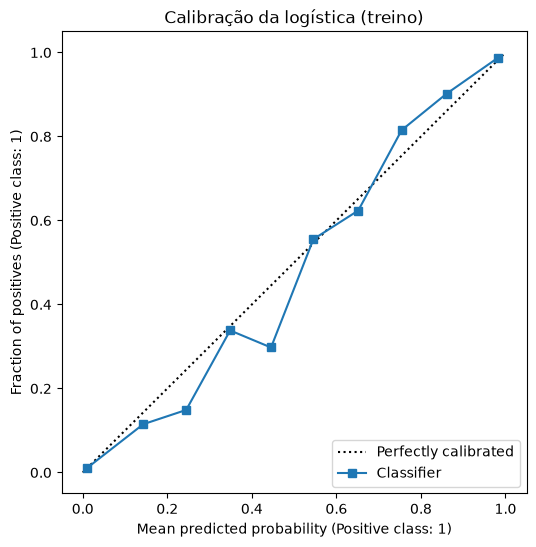

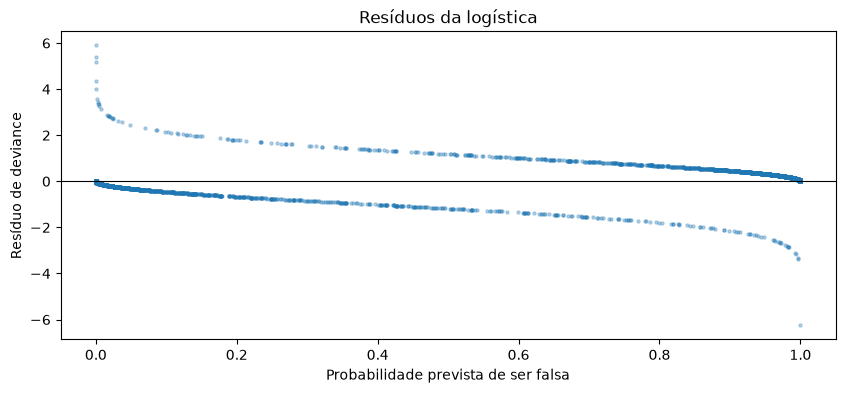

Resíduos com |valor| > 3: 16


In [9]:
prob_treino = logit.predict(X_treino_sm)

# (a) Calibração: quando o modelo diz "70% de chance", ~70% são mesmo falsas?
fig, ax = plt.subplots(figsize=(6, 6))
CalibrationDisplay.from_predictions(y_treino, prob_treino, n_bins=10, ax=ax)
ax.set_title("Calibração da logística (treino)")
plt.show()

# (b) Resíduos de deviance: procurar padrões e textos muito mal explicados
res_dev = logit.resid_dev
fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(prob_treino, res_dev, s=5, alpha=0.3)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Probabilidade prevista de ser falsa")
ax.set_ylabel("Resíduo de deviance")
ax.set_title("Resíduos da logística")
plt.show()
print("Resíduos com |valor| > 3:", (np.abs(res_dev) > 3).sum())

<h4>Validação cruzada</h4>

{'accuracy': 0.957, 'precision': 0.953, 'recall': 0.962, 'roc_auc': 0.989}


,acuracia,precisao,recall,f1,auc
modelo,,,,,
Baseline,0.500,0.00,0.000,0.000,0.500
Logística,0.943,0.93,0.958,0.944,0.988


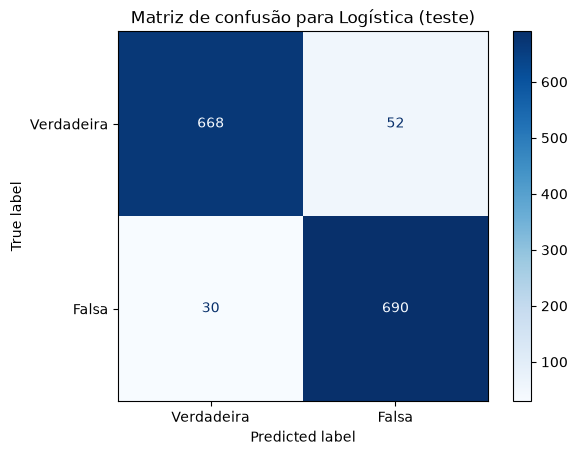

In [10]:
metricas = ["accuracy", "precision", "recall", "roc_auc"]

pipe_log = Pipeline([
    ("scaler", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000)),
])

cv_log = cross_validate(pipe_log, X_treino, y_treino, groups=grupos_treino,
                        cv=cv, scoring=metricas)
print({m: float(round(cv_log[f"test_{m}"].mean(), 3)) for m in metricas})

# Função de avaliação no teste
def avaliar(modelo, nome):
    pred = modelo.predict(X_teste)
    prob = modelo.predict_proba(X_teste)[:, 1]
    return {
        "modelo": nome,
        "acuracia": accuracy_score(y_teste, pred),
        "precisao": precision_score(y_teste, pred, zero_division=0),
        "recall": recall_score(y_teste, pred),
        "f1": f1_score(y_teste, pred),
        "auc": roc_auc_score(y_teste, prob),
    }

pipe_log.fit(X_treino, y_treino)
resultados = [avaliar(baseline, "Baseline"), avaliar(pipe_log, "Logística")]
display(pd.DataFrame(resultados).set_index("modelo").round(3))

ConfusionMatrixDisplay.from_estimator(pipe_log, X_teste, y_teste,
                                      display_labels=["Verdadeira", "Falsa"], cmap="Blues")
plt.title("Matriz de confusão para Logística (teste)")
plt.show()

<h3>Random Forest</h3>

In [11]:
rf = RandomForestClassifier(random_state=SEED, n_jobs=-1)

grade_rf = {
    "n_estimators": [300],
    "max_depth": [None, 10],
    "min_samples_leaf": [1, 5, 20],
    "max_features": ["sqrt", 0.5],
}

busca_rf = GridSearchCV(rf, grade_rf, cv=cv, scoring="roc_auc", n_jobs=-1)
busca_rf.fit(X_treino, y_treino, groups=grupos_treino)   # só treino!

print("Melhores parâmetros:", busca_rf.best_params_)
print("AUC média na validação cruzada:", round(busca_rf.best_score_, 3))

rf_final = busca_rf.best_estimator_   # já vem retreinado no treino inteiro
resultados.append(avaliar(rf_final, "Random Forest"))
display(pd.DataFrame(resultados).set_index("modelo").round(3))

Melhores parâmetros: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'n_estimators': 300}
AUC média na validação cruzada: 0.989


,acuracia,precisao,recall,f1,auc
modelo,,,,,
Baseline,0.500,0.000,0.000,0.000,0.500
Logística,0.943,0.930,0.958,0.944,0.988
Random Forest,0.949,0.941,0.957,0.949,0.988


<h3>XGBoost</h3>

In [12]:
xgb = XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=-1)

grade_xgb = {
    "n_estimators": [300],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5],
    "subsample": [0.8],
    "colsample_bytree": [0.8],
}

busca_xgb = GridSearchCV(xgb, grade_xgb, cv=cv, scoring="roc_auc", n_jobs=-1)
busca_xgb.fit(X_treino, y_treino, groups=grupos_treino)

print("Melhores parâmetros:", busca_xgb.best_params_)
print("AUC média na validação cruzada:", round(busca_xgb.best_score_, 3))

xgb_final = busca_xgb.best_estimator_
resultados.append(avaliar(xgb_final, "XGBoost"))

Melhores parâmetros: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}
AUC média na validação cruzada: 0.989


<h4>Curva ROC</h4>

,acuracia,precisao,recall,f1,auc
modelo,,,,,
Baseline,0.500,0.000,0.000,0.000,0.500
Logística,0.943,0.930,0.958,0.944,0.988
Random Forest,0.949,0.941,0.957,0.949,0.988
XGBoost,0.953,0.942,0.967,0.954,0.989


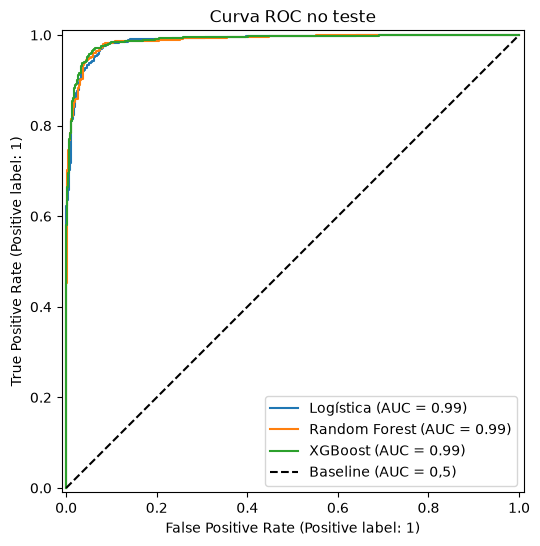

In [13]:
comparacao = pd.DataFrame(resultados).set_index("modelo").round(3)
display(comparacao)

fig, ax = plt.subplots(figsize=(7, 6))
for modelo, nome in [(pipe_log, "Logística"), (rf_final, "Random Forest"), (xgb_final, "XGBoost")]:
    RocCurveDisplay.from_estimator(modelo, X_teste, y_teste, name=nome, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Baseline (AUC = 0,5)")
ax.legend()
ax.set_title("Curva ROC no teste")
plt.show()

In [14]:
def auc_com(cols):
    pipe = Pipeline([("scaler", StandardScaler()), ("modelo", LogisticRegression(max_iter=1000))])
    pipe.fit(X_treino[cols], y_treino)
    return round(roc_auc_score(y_teste, pipe.predict_proba(X_teste[cols])[:, 1]), 3)

print("AUC só com o tamanho:", auc_com(["n_palavras"]))
print("AUC só com o estilo: ", auc_com([f for f in features if f != "log_n_palavras"]))
print("AUC com tudo:        ", auc_com(features))

AUC só com o tamanho: 0.979
AUC só com o estilo:  0.988
AUC com tudo:         0.988
